# 01 -- Exploratory analysis: what does soft-drink demand look like?

Dominick's Finer Foods (Chicago, 93 stores, Sep 1989 - May 1997), soft-drink category.
All charts are produced by `beverage_demand.viz.eda`; this notebook adds the commercial reading.
Each chart has a **So what** line written for a non-technical commercial audience.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from beverage_demand.config import results, figure
from beverage_demand.db import connect
con = connect(read_only=True)  # the DuckDB warehouse: data/warehouse.duckdb
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
from beverage_demand.viz import eda
d = eda.load()

## 0. What is in the warehouse

Everything lives in one DuckDB database built by `sql/warehouse/*.sql`. A few queries to get a
feel for the data before any modelling.

In [2]:
con.sql("""
SELECT table_name, estimated_size AS rows
FROM duckdb_tables()
WHERE table_name IN ('stg_movement', 'fact_sales_weekly', 'fact_brand_week',
                     'dim_product', 'dim_store', 'dim_calendar', 'model_panel')
ORDER BY estimated_size DESC
""").df()

,table_name,rows
0,stg_movement,17730501
1,fact_sales_weekly,2394149
2,model_panel,381397
3,fact_brand_week,5460
4,dim_product,1746
5,dim_calendar,400
6,dim_store,107


In [3]:
# top brand x pack combinations by revenue, and how much of their volume sells on promotion
con.sql("""
SELECT brand, pack,
       ROUND(SUM(dollars) / 1e6, 1)                                   AS revenue_musd,
       SUM(units)                                                     AS units,
       ROUND(SUM(units_sale_b + units_sale_s + units_sale_c + units_sale_g)
             / SUM(units), 3)                                         AS share_units_with_sale_code
FROM fact_sales_weekly
WHERE brand <> 'Other'
GROUP BY brand, pack
ORDER BY revenue_musd DESC
LIMIT 12
""").df()

,brand,pack,revenue_musd,units,share_units_with_sale_code
0,Pepsi,24pk can,39.4,6.595e+06,0.789
1,Coke,24pk can,26.5,4.387e+06,0.752
2,Diet Pepsi,24pk can,17.8,2.954e+06,0.784
3,Diet Coke,24pk can,15.3,2.498e+06,0.736
4,Pepsi,2L,13.6,1.187e+07,0.711
5,Pepsi,12pk can,12.4,3.604e+06,0.705
6,Coke,2L,12.3,1.095e+07,0.649
7,Diet Coke,12pk can,11.0,3.255e+06,0.659
8,7Up,24pk can,10.9,1.939e+06,0.832
9,Diet Coke,2L,10.6,9.035e+06,0.711


In [4]:
# year-over-year revenue growth per brand with a window function
con.sql("""
WITH yearly AS (
    SELECT f.brand, c.year, SUM(f.dollars) AS revenue
    FROM fact_sales_weekly f JOIN dim_calendar c USING (week)
    WHERE c.year BETWEEN 1990 AND 1996 AND f.brand IN ('Coke', 'Pepsi', 'Private Label')
    GROUP BY f.brand, c.year
)
SELECT brand, year, ROUND(revenue / 1e6, 2) AS revenue_musd,
       ROUND(revenue / LAG(revenue) OVER (PARTITION BY brand ORDER BY year) - 1, 3) AS yoy_growth
FROM yearly ORDER BY brand, year
""").df()

,brand,year,revenue_musd,yoy_growth
0,Coke,1990,5.29,NaN
1,Coke,1991,6.50,0.230
2,Coke,1992,5.92,-0.090
3,Coke,1993,6.52,0.101
4,Coke,1994,6.56,0.006
5,Coke,1995,10.49,0.600
6,Coke,1996,11.08,0.057
7,Pepsi,1990,9.38,NaN
8,Pepsi,1991,8.68,-0.074
9,Pepsi,1992,8.68,0.000


**So what:** Coke and Pepsi in 24-packs and 2-litres are the money makers, and for them the
majority of units carry a sale code -- before even looking at prices, the data say this is a
promotion-driven category.

## 1. Volume trend by brand

In [5]:
share = eda.volume_trend(d["brand_week"])
share.head(10)

,volume_share
brand,
Other,0.210
Pepsi,0.171
Coke,0.119
Diet Pepsi,0.093
Diet Coke,0.093
Private Label,0.091
7Up,0.057
RC Cola,0.039
Diet Rite,0.037


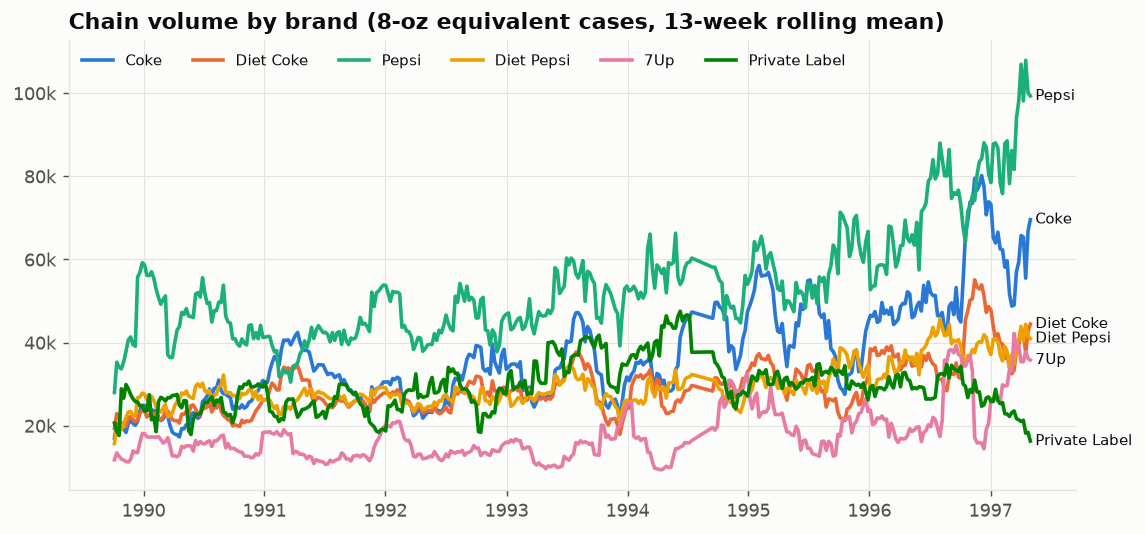

In [6]:
Image(filename=str(figure("eda_volume_trend.png")))

**So what:** Pepsi is the biggest single brand (about 17% of category volume vs. 12% for Coke) and
grew steadily into 1997, while Dominick's private label lost ground after 1995. Brand-level
strategy matters: the same price move will not play out the same way for every brand.

## 2. Seasonality and holidays

In [7]:
season = eda.seasonality(d["brand_week"], d["cal"])
season

,holiday_vs_avg,summer_vs_avg,winter_vs_avg
holiday_name,,,
new_year,0.120,0.073,-0.081
super_bowl,0.119,0.073,-0.081
presidents_day,-0.103,0.073,-0.081
easter,0.087,0.073,-0.081
memorial_day,0.269,0.073,-0.081
july_4,0.370,0.073,-0.081
labor_day,0.317,0.073,-0.081
halloween,-0.046,0.073,-0.081
thanksgiving,-0.146,0.073,-0.081


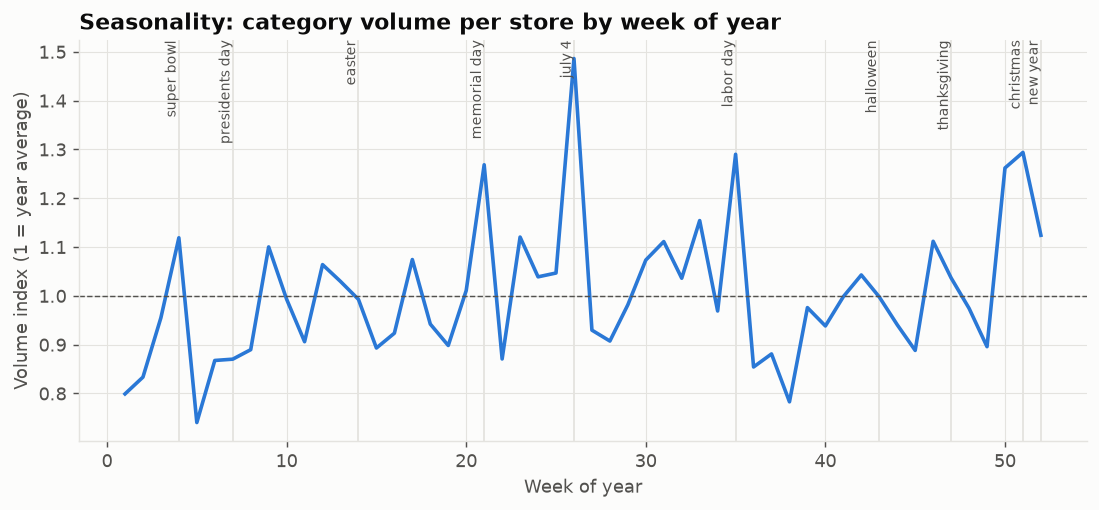

In [8]:
Image(filename=str(figure("eda_seasonality.png")))

**So what:** Summer holidays are the category's peak weeks -- July 4th weeks run roughly 37% above
an average week, Labor Day about 32% and Memorial Day about 27%, with Christmas/New Year close
behind. Thanksgiving and Presidents' Day weeks are *below* average. Promotion calendars and
inventory plans should be built around these weeks, and forecasts must know about them.

## 3. How often, how deep, and how much volume is promoted

In [9]:
promo = eda.promo_frequency(d["panel"])
promo

,promo_week_share,avg_depth,units_on_promo_share
series,,,
Private Label | 2L,0.473,0.258,0.786
Diet Coke | 2L,0.564,0.241,0.806
7Up | 2L,0.548,0.241,0.809
Diet Pepsi | 2L,0.567,0.239,0.826
Pepsi | 2L,0.572,0.236,0.836
Coke | 2L,0.659,0.219,0.859
Diet Coke | 24pk can,0.435,0.204,0.892
Diet Pepsi | 24pk can,0.505,0.204,0.913
Private Label | 24pk can,0.483,0.241,0.919


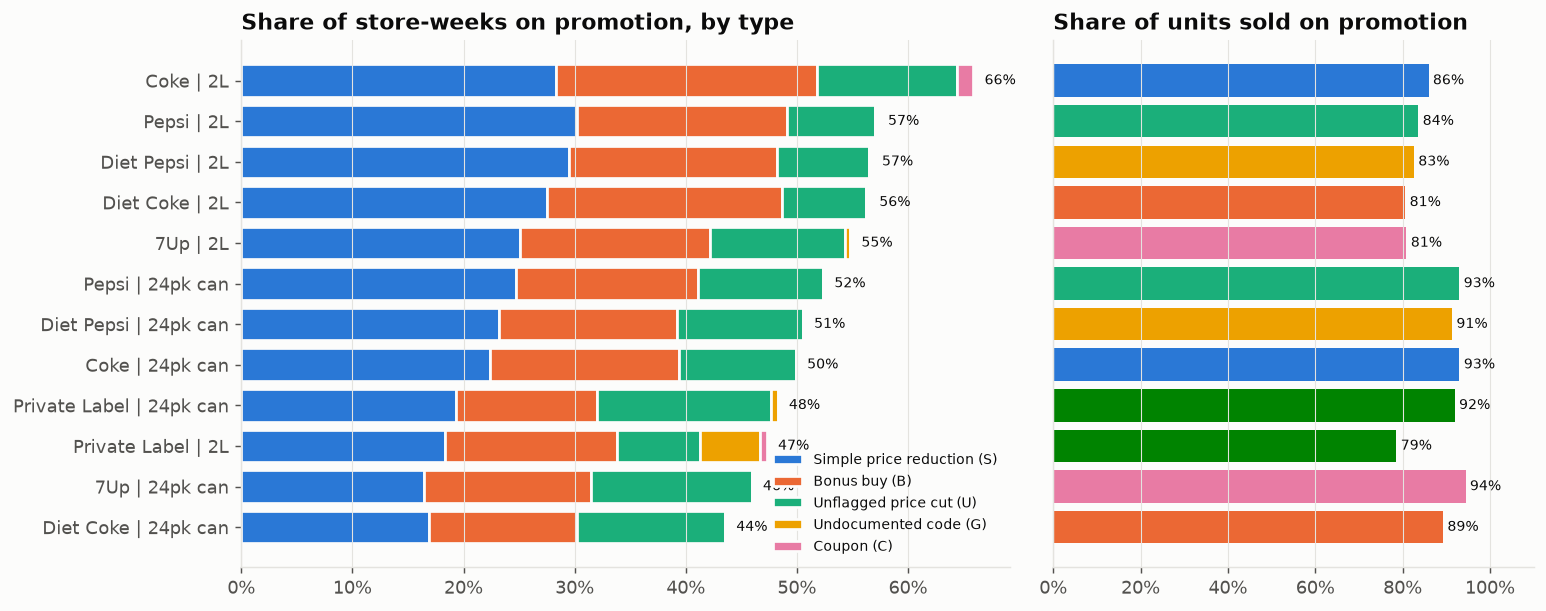

In [10]:
Image(filename=str(figure("eda_promo_frequency.png")))

**So what:** This is a promotion-driven category: the core brands are on some kind of deal in
43-66% of store-weeks, at an average depth of about 20-26%, and **79-94% of all units are sold
on promotion** (24-packs are the most dependent). Regular-price sales are the exception, which is
why promotion effectiveness and trade-spend ROI matter as much as list price.

## 4. Price vs. volume -- a first look at elasticity

In [11]:
pd.concat([eda.price_volume(d["panel"], "2L"), eda.price_volume(d["panel"], "24pk can")], axis=1)

,raw_log_log_slope_2L,raw_log_log_slope_24pk can
Coke,-3.625,-6.693
Diet Coke,-3.187,-6.339
Pepsi,-3.764,-6.966
Diet Pepsi,-3.598,-6.630
7Up,-3.148,-6.277
Private Label,-3.152,-4.854


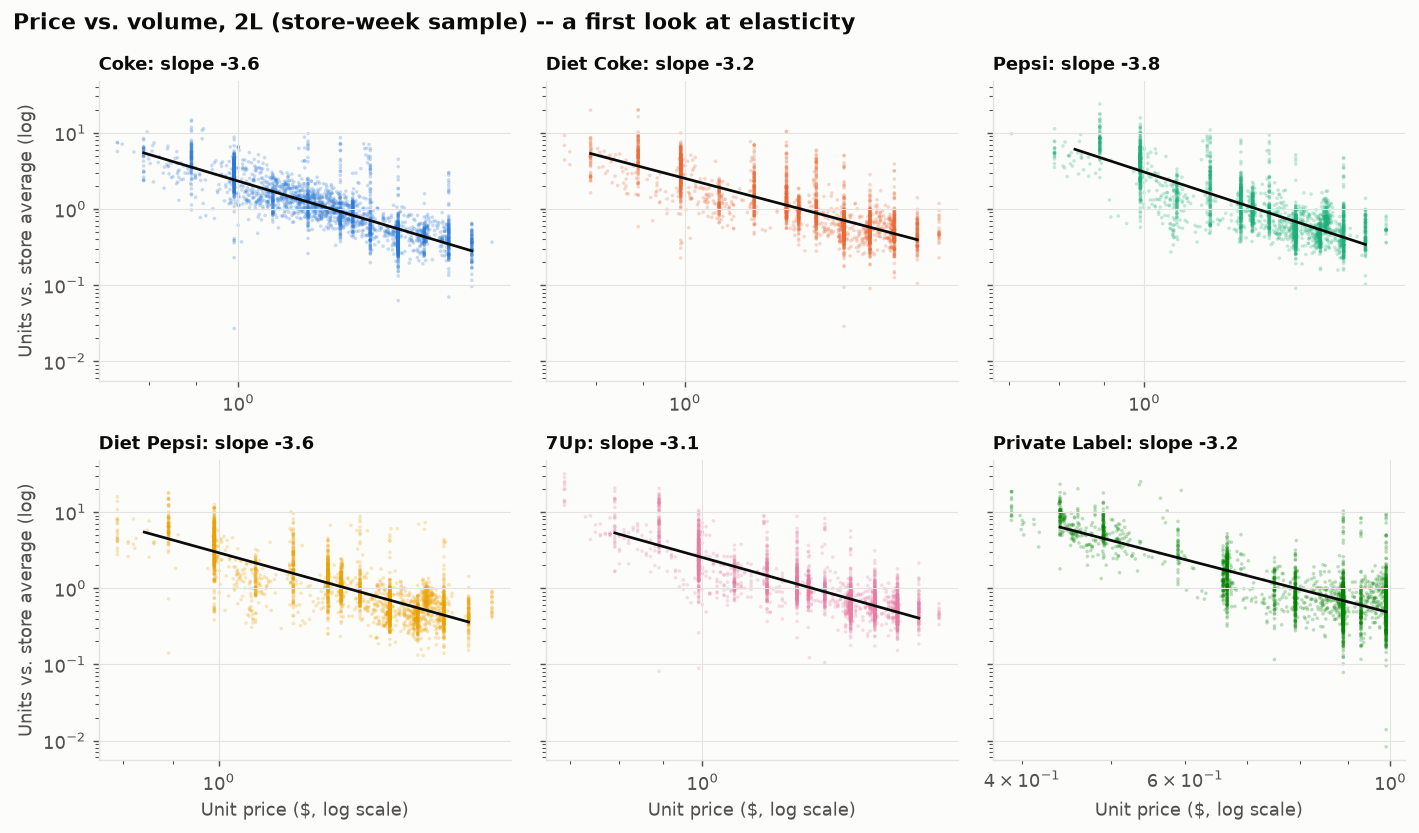

In [12]:
Image(filename=str(figure("eda_price_volume_2L.png")))

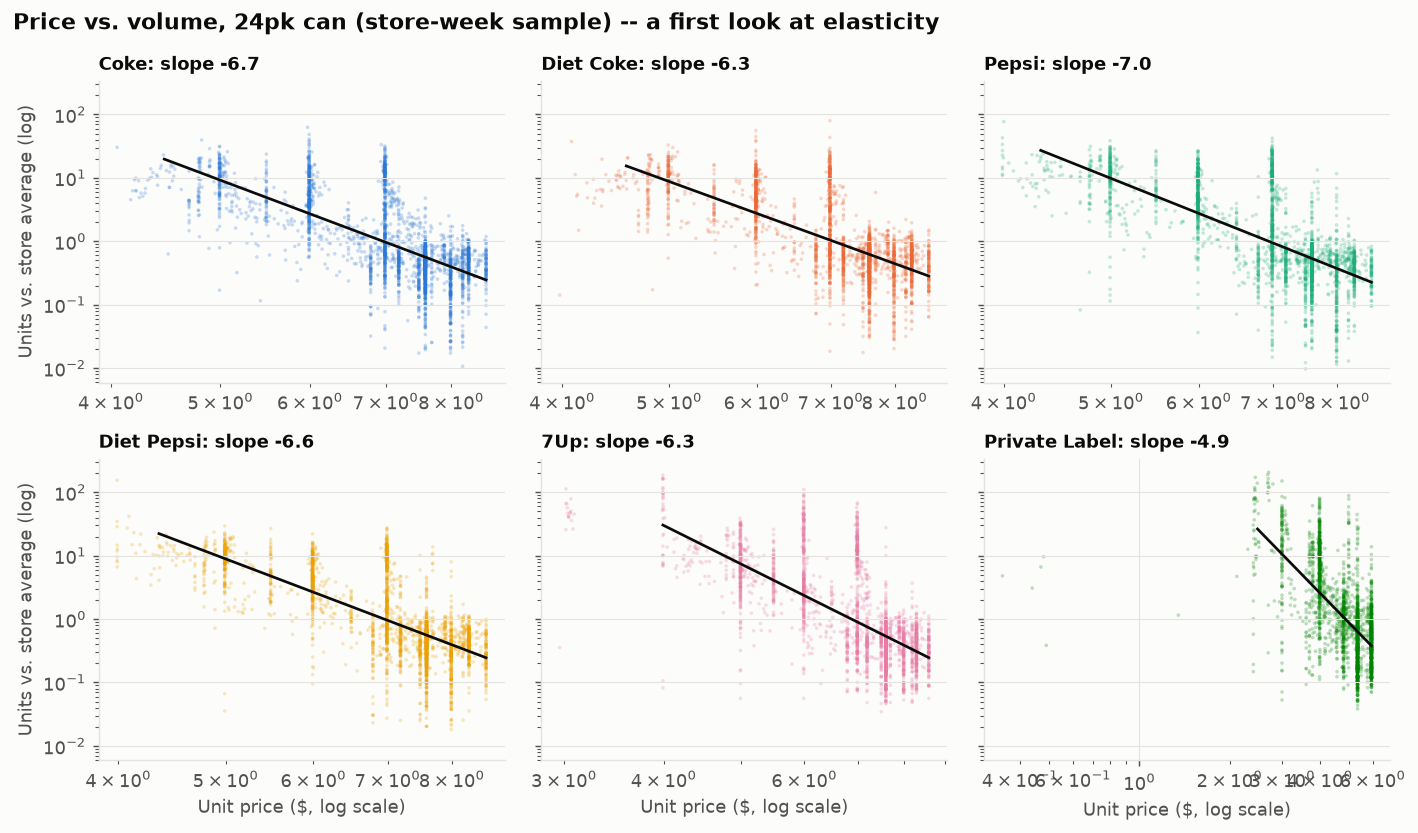

In [13]:
Image(filename=str(figure("eda_price_volume_24pk_can.png")))

**So what:** On a log-log scale volume falls almost linearly as price rises, and steeply: the raw
slopes are about -3 to -4 for 2-litre bottles and -5 to -7 for 24-pack cans. Shoppers react
strongly to price -- especially on the large can packs that they can stock up on. These raw slopes
mix price with promotion displays and seasonality, so notebook 02 estimates the elasticity
properly with those effects controlled.